# Classification Analysis

## 1. Introduction

This notebook aims to train supervised machine learning models to classify mammography cases into three pathology categories:

- BENIGN
- BENIGN_WITHOUT_CALLBACK
- MALIGNANT

The prepared training and testing datasets will be used to train and evaluate different classification algorithms.

## 2. Loading Prepared Data

Load the preprocessed feature matrices and their corresponding target labels for both Mass and Calcification datasets.

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import load_npz

mass_X_train = load_npz("../data/processed/mass_X_train.npz")
mass_X_test = load_npz("../data/processed/mass_X_test.npz")

calc_X_train = load_npz("../data/processed/calc_X_train.npz")
calc_X_test = load_npz("../data/processed/calc_X_test.npz")

mass_y_train = np.load("../data/processed/mass_y_train.npy")
mass_y_test = np.load("../data/processed/mass_y_test.npy")

calc_y_train = np.load("../data/processed/calc_y_train.npy")
calc_y_test = np.load("../data/processed/calc_y_test.npy")

print("Mass:", mass_X_train.shape, mass_X_test.shape)
print("Calcification:", calc_X_train.shape, calc_X_test.shape)

Mass: (1054, 40) (264, 40)
Calcification: (1237, 52) (309, 52)


## 3. Training Classification Models

Train two supervised learning algorithms on both datasets:

- Logistic Regression
- Random Forest

The models will learn to predict the pathology class using the prepared clinical features.

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

results = {}

for dataset_name, X_train, y_train in [
    ("Mass", mass_X_train, mass_y_train),
    ("Calcification", calc_X_train, calc_y_train)
]:
    models = {
        "Logistic Regression": LogisticRegression(
            max_iter=1000,
            random_state=42
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight="balanced"
        )
    }

    results[dataset_name] = {}

    for model_name, model in models.items():
        model.fit(X_train, y_train)
        results[dataset_name][model_name] = model

        print(f"{dataset_name} - {model_name}: trained")

Mass - Logistic Regression: trained
Mass - Random Forest: trained
Calcification - Logistic Regression: trained
Calcification - Random Forest: trained


## Saving Trained Classification Models

Save the four trained classification models to reuse them later
for evaluation on the official test datasets and integration into
the final application.

In [40]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    results["Mass"]["Logistic Regression"],
    "../models/mass_logistic_regression.joblib"
)

joblib.dump(
    results["Mass"]["Random Forest"],
    "../models/mass_random_forest.joblib"
)

joblib.dump(
    results["Calcification"]["Logistic Regression"],
    "../models/calc_logistic_regression.joblib"
)

joblib.dump(
    results["Calcification"]["Random Forest"],
    "../models/calc_random_forest.joblib"
)

print("All four classification models saved successfully.")

All four classification models saved successfully.


In [42]:
import os

for file in os.listdir("../models"):
    print(file)

calc_logistic_regression.joblib
calc_preprocessor.joblib
calc_random_forest.joblib
mass_logistic_regression.joblib
mass_preprocessor.joblib
mass_random_forest.joblib


## 4. Model Evaluation

Evaluate the trained models using the test datasets.

The following metrics will be used:

- Accuracy
- Precision
- Recall
- F1-score

These metrics provide a comprehensive evaluation of classification performance.

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

evaluation_results = []

for dataset_name, X_test, y_test in [
    ("Mass", mass_X_test, mass_y_test),
    ("Calcification", calc_X_test, calc_y_test)
]:
    for model_name, model in results[dataset_name].items():
        y_pred = model.predict(X_test)

        evaluation_results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(
                y_test, y_pred, average="macro", zero_division=0
            ),
            "Recall": recall_score(
                y_test, y_pred, average="macro", zero_division=0
            ),
            "F1-score": f1_score(
                y_test, y_pred, average="macro", zero_division=0
            )
        })

evaluation_df = pd.DataFrame(evaluation_results)

print (evaluation_df.round(3))

         Dataset                Model  Accuracy  Precision  Recall  F1-score
0           Mass  Logistic Regression     0.814      0.810   0.746     0.771
1           Mass        Random Forest     0.746      0.680   0.737     0.699
2  Calcification  Logistic Regression     0.699      0.704   0.710     0.700
3  Calcification        Random Forest     0.647      0.651   0.661     0.654


## 5. Model Performance Visualization

Compare the classification models using their accuracy and macro F1-score.

This visualization helps identify the best-performing model for each dataset.

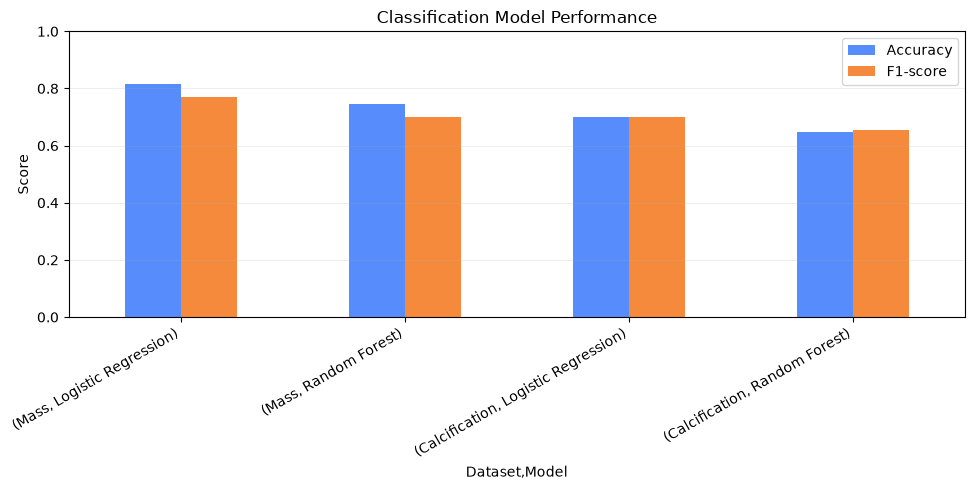

In [38]:
metrics = ["Accuracy", "F1-score"]

evaluation_df.set_index(
    ["Dataset", "Model"]
)[metrics].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Classification Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Confusion Matrix

Evaluate the classification results using confusion matrices.

These matrices show the number of correct and incorrect predictions for each pathology class.

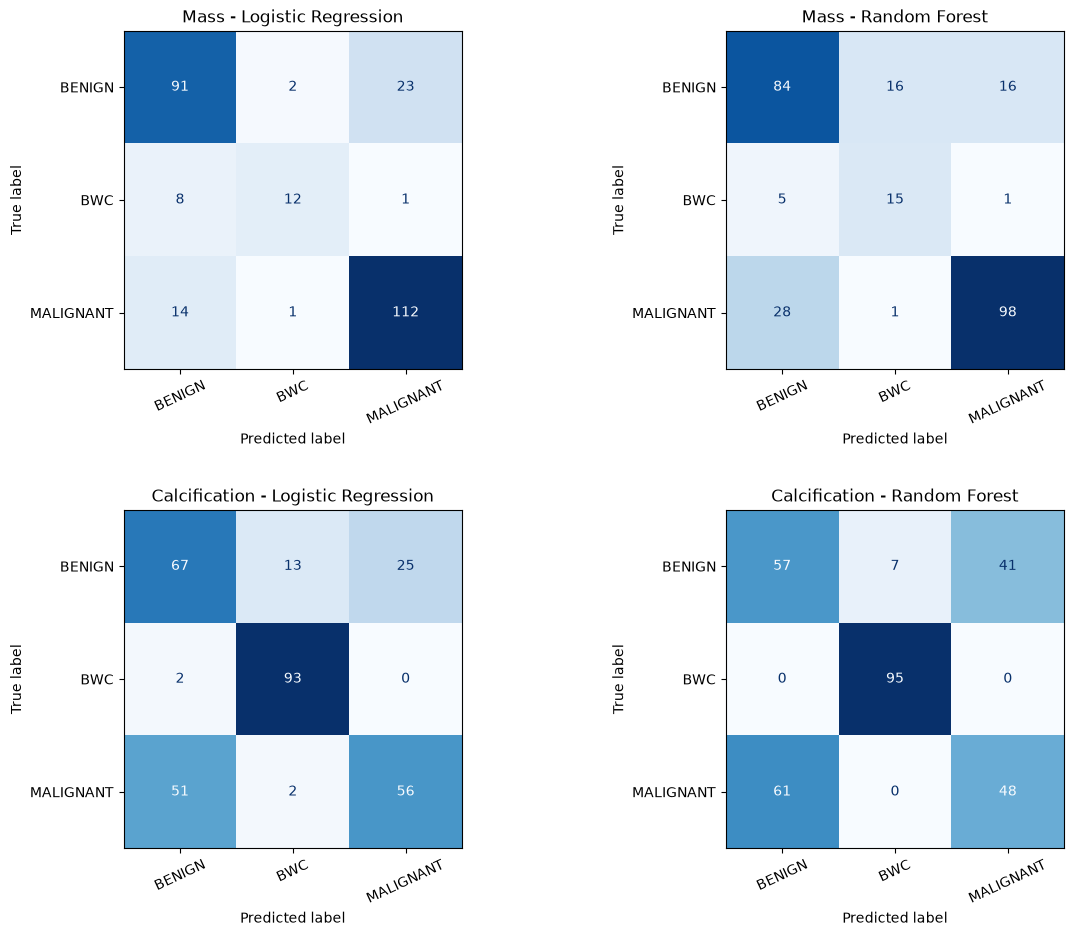

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

datasets = [
    ("Mass", mass_X_test, mass_y_test),
    ("Calcification", calc_X_test, calc_y_test)
]

for i, (dataset_name, X_test, y_test) in enumerate(datasets):
    for j, (model_name, model) in enumerate(results[dataset_name].items()):

        y_pred = model.predict(X_test)

        cm = confusion_matrix(y_test, y_pred)

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["BENIGN", "BWC", "MALIGNANT"]
        )

        disp.plot(
            ax=axes[i, j],
            cmap="Blues",
            colorbar=False,
            values_format="d"
        )

        axes[i, j].set_title(f"{dataset_name} - {model_name}")
        axes[i, j].tick_params(axis="x", labelrotation=25)

plt.tight_layout(pad=3)
plt.show()

## 7. Results Interpretation

### 7.1 Mass Dataset

Logistic Regression achieved the best overall performance, with an accuracy of 81.4% and a macro F1-score of 77.1%.

Key observations:

- BENIGN cases were correctly identified in 78.4% of cases.
- BENIGN_WITHOUT_CALLBACK achieved a recall of 57.1%, indicating difficulties in identifying this minority class.
- MALIGNANT cases achieved a recall of 88.2%, showing better detection performance than in the Calcification dataset.
- Random Forest achieved lower overall performance, despite a higher recall for BENIGN_WITHOUT_CALLBACK.

### 7.2 Calcification Dataset

Logistic Regression also outperformed Random Forest, achieving an accuracy of 69.9% and a macro F1-score of 70.0%.

Key observations:

- BENIGN cases achieved a recall of 63.8%.
- BENIGN_WITHOUT_CALLBACK was identified with a high recall of 97.9%.
- MALIGNANT cases achieved a recall of only 51.4%, indicating difficulty distinguishing malignant cases from the other classes.
- Random Forest showed lower overall performance and a lower recall for MALIGNANT cases.

### 7.3 Comparison Between Datasets

The Mass dataset achieved better classification performance than the Calcification dataset.

Logistic Regression obtained:

- 81.4% accuracy on Mass.
- 69.9% accuracy on Calcification.
- 88.2% malignant recall on Mass.
- 51.4% malignant recall on Calcification.

These differences suggest that the selected clinical features provide more useful information for distinguishing pathology classes in the Mass dataset.

### 7.4 Limitations and Possible Improvements

Several limitations should be considered:

- Class imbalance, particularly for BENIGN_WITHOUT_CALLBACK in the Mass dataset.
- Difficulty distinguishing BENIGN and MALIGNANT cases in the Calcification dataset.
- Limited dataset size, which may affect the stability of evaluation results.

Possible improvements include:

- Testing additional algorithms such as SVM and Gradient Boosting.
- Applying class weighting to address class imbalance.
- Performing cross-validation to assess model stability.
- Exploring additional clinical features.

**Note:** These models are experimental classification systems based on clinical descriptors. Their results should not be interpreted as evidence of clinical diagnostic reliability.